## 1. Environment Setup and Imports

In [3]:
from datasets import load_dataset, Dataset
import pandas as pd
import numpy as np
import re
import torch
import torch.nn as nn
from transformers import XLMRobertaModel, AutoTokenizer, Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
print("Imported....")

Imported....


## 2. Dual-Head Model Architecture (shared XLM-R encoder, separate sentiment and intent classification heads)

In [4]:
class DualHeadXLMR(nn.Module):
    def __init__(self, model_name="xlm-roberta-base", num_sentiment_labels=3, num_intent_labels=3):
        super().__init__()
        self.encoder = XLMRobertaModel.from_pretrained(model_name)
        hidden_size = self.encoder.config.hidden_size

        self.dropout = nn.Dropout(0.1)
        self.sentiment_head = nn.Linear(hidden_size, num_sentiment_labels)
        self.intent_head = nn.Linear(hidden_size, num_intent_labels)

    def forward(self, input_ids, attention_mask, task=None, labels=None):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        pooled = outputs.last_hidden_state[:, 0, :]
        pooled = self.dropout(pooled)

        sentiment_logits = self.sentiment_head(pooled)
        intent_logits = self.intent_head(pooled)

        loss = None
        if labels is not None and task is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = torch.tensor(0.0, device=pooled.device)

            sentiment_mask = (task == 0)
            intent_mask = (task == 1)

            if sentiment_mask.any():
                loss = loss + loss_fct(sentiment_logits[sentiment_mask], labels[sentiment_mask])
            if intent_mask.any():
                loss = loss + loss_fct(intent_logits[intent_mask], labels[intent_mask])

        return {
            "loss": loss,
            "sentiment_logits": sentiment_logits,
            "intent_logits": intent_logits
        }

print("Done...")

Done...


## 3. Rebuild Intent Dataset (Inquiry/Opinion/Factual, from Questions-vs-Statements + SetFit/subj, with adversarial augmentation)

In [5]:
questions_statements = load_dataset("jonaskoenig/Questions-vs-Statements-Classification")
subj_obj = load_dataset("SetFit/subj")

def extract_last_question(text):
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    sentences = [s.strip() for s in sentences if s.strip()]
    for sent in reversed(sentences):
        if sent.endswith('?'):
            return sent
    if sentences:
        return sentences[-1]
    return text.strip()

inquiry_texts = questions_statements["train"].filter(lambda x: x["labels"] == 1)["text"]
inquiry_df = pd.DataFrame({"text": inquiry_texts, "intent": "Inquiry"})
inquiry_df["text"] = inquiry_df["text"].apply(extract_last_question)

opinion_texts = subj_obj["train"].filter(lambda x: x["label_text"] == "subjective")["text"]
opinion_df = pd.DataFrame({"text": opinion_texts, "intent": "Opinion"})

factual_texts = subj_obj["train"].filter(lambda x: x["label_text"] == "objective")["text"]
factual_df = pd.DataFrame({"text": factual_texts, "intent": "Factual"})

min_size = min(len(inquiry_df), len(opinion_df), len(factual_df))
inquiry_df = inquiry_df.sample(min_size, random_state=42)
opinion_df = opinion_df.sample(min_size, random_state=42)
factual_df = factual_df.sample(min_size, random_state=42)

rhetorical_opinions = [
    "Don't you think this movie was absolutely terrible?", "Isn't it obvious that this policy will fail?",
    "Wouldn't you agree that this is the best phone on the market?", "Isn't this restaurant clearly overrated?",
    "Don't you think the referee made the wrong call?", "Isn't it clear that this book is a masterpiece?",
    "Wouldn't anyone say this traffic is ridiculous?", "Isn't this the worst customer service you've ever seen?",
    "Don't you agree that this song is incredibly catchy?", "Isn't it crazy how expensive this city has become?",
    "Wouldn't you say this team deserved to win?", "Isn't this weather absolutely miserable?",
    "Don't you think the new update made things worse?", "Isn't it frustrating how slow this app is?",
    "Wouldn't you call this the greatest concert ever?", "Isn't it amazing how good this coffee tastes?",
    "Don't you think the plot twist was predictable?", "Isn't this laptop way overpriced for what it offers?",
    "Wouldn't you say the service here is excellent?", "Isn't it obvious this decision was a mistake?",
    "Don't you think the acting in this film was brilliant?", "Isn't this the most boring lecture you've attended?",
    "Wouldn't anyone agree this hotel exceeded expectations?", "Isn't it unfair how this rule was enforced?",
    "Don't you feel this design looks outdated?", "Isn't it ridiculous how long the wait was?",
    "Wouldn't you say this is a waste of money?", "Isn't the view from here absolutely breathtaking?",
    "Don't you think this candidate lacks experience?", "Isn't it obvious that this product is poorly made?",
]
varied_factual = [
    "This phone has a 5000mAh battery.", "The meeting is scheduled for 3 PM tomorrow.",
    "This laptop comes with 16GB of RAM.", "The train departs from platform 4.",
    "This recipe requires two cups of flour.", "The store closes at 9 PM on weekdays.",
    "This car has a fuel efficiency of 18 km per liter.", "The conference will be held in Hall B.",
    "This jacket is made of 100% cotton.", "The package was delivered on Tuesday.",
    "This router supports dual-band WiFi.", "The flight duration is approximately six hours.",
    "This medicine should be taken twice daily.", "The building has twelve floors.",
    "This printer uses ink cartridges, not toner.", "The exam starts at 10 AM sharp.",
    "This bridge spans two kilometers.", "The software update was released last week.",
    "This camera has a 48-megapixel sensor.", "The library is open until 8 PM.",
]

new_opinion_rows = pd.DataFrame({"text": rhetorical_opinions, "intent": "Opinion"})
new_factual_rows = pd.DataFrame({"text": varied_factual, "intent": "Factual"})

intent_df_augmented = pd.concat([inquiry_df, opinion_df, factual_df, new_opinion_rows, new_factual_rows], ignore_index=True)
intent_df_augmented = intent_df_augmented.sample(frac=1, random_state=42).reset_index(drop=True)

intent_label_map = {"Inquiry": 0, "Opinion": 1, "Factual": 2}
intent_df_augmented["label"] = intent_df_augmented["intent"].map(intent_label_map)

print(intent_df_augmented["intent"].value_counts())
print(f"Total: {len(intent_df_augmented)}")

README.md:   0%|          | 0.00/2.35k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.csv: reconstructing file:   0%|          |  0.00B / 19.6MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/6.50M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/126909 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8000 [00:00<?, ? examples/s]

intent
Opinion    3997
Factual    3987
Inquiry    3967
Name: count, dtype: int64
Total: 11951


## 4. Load Sentiment Data and Build Combined Multi-Task Dataset

In [6]:
sentiment_raw = load_dataset("cardiffnlp/tweet_eval", "sentiment")

sentiment_train_df = pd.DataFrame({
    "text": sentiment_raw["train"]["text"],
    "label": sentiment_raw["train"]["label"],
    "task": 0
})

intent_train_df = pd.DataFrame({
    "text": intent_df_augmented["text"],
    "label": intent_df_augmented["label"],
    "task": 1
})

combined_df = pd.concat([sentiment_train_df, intent_train_df], ignore_index=True)
combined_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Total combined examples: {len(combined_df)}")
print(combined_df["task"].value_counts())

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Total combined examples: 57566
task
0    45615
1    11951
Name: count, dtype: int64


## 5. Tokenize Combined Dataset

In [7]:
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")

train_df, test_df = train_test_split(
    combined_df, test_size=0.1, random_state=42, stratify=combined_df["task"]
)

train_dataset = Dataset.from_pandas(train_df[["text", "label", "task"]].reset_index(drop=True))
test_dataset = Dataset.from_pandas(test_df[["text", "label", "task"]].reset_index(drop=True))

def tokenize_fn(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=128)

train_tokenized = train_dataset.map(tokenize_fn, batched=True)
test_tokenized = test_dataset.map(tokenize_fn, batched=True)

print(train_tokenized)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/51809 [00:00<?, ? examples/s]

Map:   0%|          | 0/5757 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'task', 'input_ids', 'attention_mask'],
    num_rows: 51809
})


## 6. Custom Multi-Task Trainer (routes each example's loss to the correct head based on its task)

In [8]:
class MultiTaskTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        task = inputs.pop("task")
        outputs = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            task=task,
            labels=labels
        )
        loss = outputs["loss"]
        return (loss, outputs) if return_outputs else loss
print("Defined...")        
        

Defined...


## 7. Initialize Model and Training Configuration

In [9]:
model = DualHeadXLMR(num_sentiment_labels=3, num_intent_labels=3)

total_steps_dh = (len(train_tokenized) // 16) * 3
warmup_steps_dh = int(0.1 * total_steps_dh)
print(f"Total steps: {total_steps_dh}, Warmup steps: {warmup_steps_dh}")

training_args = TrainingArguments(
    output_dir="./dualhead-results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=warmup_steps_dh,
    fp16=True,
    save_total_limit=1,
    remove_unused_columns=False
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total steps: 9714, Warmup steps: 971


## 8. Training the Dual-Head Model

In [10]:
trainer = MultiTaskTrainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
)

trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss
1,0.847747,0.878711
2,0.678126,0.806355
3,0.514359,0.799208


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


TrainOutput(global_step=4860, training_loss=0.7676894702047968, metrics={'train_runtime': 3028.5798, 'train_samples_per_second': 51.32, 'train_steps_per_second': 1.605, 'total_flos': 0.0, 'train_loss': 0.7676894702047968, 'epoch': 3.0})

## 9. Evaluate Both Heads on English Test Set

In [11]:
def evaluate_task(trainer, test_df, task_id, task_name, label_names):
    task_subset = test_df[test_df["task"] == task_id].reset_index(drop=True)
    task_dataset = Dataset.from_pandas(task_subset[["text", "label", "task"]])
    task_tokenized = task_dataset.map(tokenize_fn, batched=True)

    model.eval()
    all_logits = []
    device = next(model.parameters()).device

    with torch.no_grad():
        for i in range(0, len(task_tokenized), 32):
            batch = task_tokenized[i:i+32]
            input_ids = torch.tensor(batch["input_ids"]).to(device)
            attention_mask = torch.tensor(batch["attention_mask"]).to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)

            logits = outputs["sentiment_logits"] if task_name == "sentiment" else outputs["intent_logits"]
            all_logits.append(logits.cpu().numpy())

    all_logits = np.concatenate(all_logits, axis=0)
    predictions = np.argmax(all_logits, axis=1)
    true_labels = task_subset["label"].values

    acc = accuracy_score(true_labels, predictions)
    f1_macro = f1_score(true_labels, predictions, average="macro")
    f1_micro = f1_score(true_labels, predictions, average="micro")

    print(f"{task_name.capitalize()} — Accuracy: {acc:.4f}, F1 Macro: {f1_macro:.4f}, F1 Micro: {f1_micro:.4f}")
    return acc, f1_macro, f1_micro

sentiment_acc, sentiment_f1_macro, sentiment_f1_micro = evaluate_task(trainer, test_df, task_id=0, task_name="sentiment", label_names=["negative","neutral","positive"])
intent_acc, intent_f1_macro, intent_f1_micro = evaluate_task(trainer, test_df, task_id=1, task_name="intent", label_names=["Inquiry","Opinion","Factual"])

Map:   0%|          | 0/4562 [00:00<?, ? examples/s]

Sentiment — Accuracy: 0.7304, F1 Macro: 0.7187, F1 Micro: 0.7304


Map:   0%|          | 0/1195 [00:00<?, ? examples/s]

Intent — Accuracy: 0.9707, F1 Macro: 0.9710, F1 Micro: 0.9707


## 10. Save Dual-Head Model

In [12]:
model.encoder.save_pretrained("/kaggle/working/dualhead-encoder")
torch.save(model.state_dict(), "/kaggle/working/dualhead-full-model.pt") 
tokenizer.save_pretrained("/kaggle/working/dualhead-encoder")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/dualhead-encoder/tokenizer_config.json',
 '/kaggle/working/dualhead-encoder/tokenizer.json')

## 11. Confidence Scoring (Softmax Probabilities)

In [13]:
import torch.nn.functional as F

def evaluate_task_with_confidence(trainer, test_df, task_id, task_name, label_names):
    task_subset = test_df[test_df["task"] == task_id].reset_index(drop=True)
    task_dataset = Dataset.from_pandas(task_subset[["text", "label", "task"]])
    task_tokenized = task_dataset.map(tokenize_fn, batched=True)

    model.eval()
    all_logits = []
    device = next(model.parameters()).device

    with torch.no_grad():
        for i in range(0, len(task_tokenized), 32):
            batch = task_tokenized[i:i+32]
            input_ids = torch.tensor(batch["input_ids"]).to(device)
            attention_mask = torch.tensor(batch["attention_mask"]).to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)

            logits = outputs["sentiment_logits"] if task_name == "sentiment" else outputs["intent_logits"]
            all_logits.append(logits.cpu().numpy())

    all_logits = np.concatenate(all_logits, axis=0)
    predictions = np.argmax(all_logits, axis=1)
    true_labels = task_subset["label"].values

    probs = F.softmax(torch.tensor(all_logits), dim=1)
    confidence = probs.max(dim=1).values.numpy()

    acc = accuracy_score(true_labels, predictions)
    f1_macro = f1_score(true_labels, predictions, average="macro")
    f1_micro = f1_score(true_labels, predictions, average="micro")

    print(f"{task_name.capitalize()} — Accuracy: {acc:.4f}, F1 Macro: {f1_macro:.4f}, F1 Micro: {f1_micro:.4f}")
    print(f"Average confidence: {confidence.mean():.4f}")
    print(f"Sample predictions with confidence:")
    for i in range(5):
        print(f"  Text: {task_subset['text'].iloc[i][:60]}")
        print(f"    True: {label_names[true_labels[i]]} | Predicted: {label_names[predictions[i]]} | Confidence: {confidence[i]:.2%}")

    return acc, f1_macro, f1_micro, predictions, confidence

sentiment_acc, sentiment_f1_macro, sentiment_f1_micro, sentiment_preds, sentiment_conf = evaluate_task_with_confidence(
    trainer, test_df, task_id=0, task_name="sentiment", label_names=["negative","neutral","positive"]
)
intent_acc, intent_f1_macro, intent_f1_micro, intent_preds, intent_conf = evaluate_task_with_confidence(
    trainer, test_df, task_id=1, task_name="intent", label_names=["Inquiry","Opinion","Factual"]
)

Map:   0%|          | 0/4562 [00:00<?, ? examples/s]

Sentiment — Accuracy: 0.7304, F1 Macro: 0.7187, F1 Micro: 0.7304
Average confidence: 0.8147
Sample predictions with confidence:
  Text: @user Now you got me on the hunt for tickets event in Housto
    True: positive | Predicted: positive | Confidence: 93.39%
  Text: Scott & Evelyn Swanson\u002c both work for FEMA.  Happy to h
    True: positive | Predicted: positive | Confidence: 99.09%
  Text: Egypt&#039;s new president Mohamed Morsi on Monday described
    True: neutral | Predicted: neutral | Confidence: 93.13%
  Text: "It's a busy Monday. Dangerously hot. NFL legend Frank Giffo
    True: negative | Predicted: negative | Confidence: 89.91%
  Text: @user @user man, looks like it wwont even be ready by the ti
    True: negative | Predicted: negative | Confidence: 84.88%


Map:   0%|          | 0/1195 [00:00<?, ? examples/s]

Intent — Accuracy: 0.9707, F1 Macro: 0.9710, F1 Micro: 0.9707
Average confidence: 0.9931
Sample predictions with confidence:
  Text: talk to her is not the perfect movie many have made it out t
    True: Opinion | Predicted: Opinion | Confidence: 99.96%
  Text: a determined , ennui-hobbled slog that really does n't have 
    True: Opinion | Predicted: Opinion | Confidence: 99.97%
  Text: a young reporter named rachel is investigating these events 
    True: Factual | Predicted: Factual | Confidence: 99.98%
  Text: true to its animatronic roots : . . . as stiff , ponderous a
    True: Opinion | Predicted: Opinion | Confidence: 99.98%
  Text: a man ( phillipe ) awakens in a hospital not recalling the l
    True: Factual | Predicted: Factual | Confidence: 99.99%


## 12. Cross-Lingual Sentiment Evaluation (5 languages, using dual-head model)

In [14]:
from datasets import load_dataset

languages = ["hi", "bn", "ta", "te", "mr"]
all_data = {}
for lang in languages:
    all_data[lang] = load_dataset(
        "ai4bharat/IndicSentiment",
        revision="refs/convert/parquet",
        data_dir=f"translation-{lang}"
    )

def evaluate_sentiment_crosslingual(lang_code, all_data, binary_forced=True):
    test_data = all_data[lang_code]["test"].filter(lambda x: x["LABEL"] is not None)
    
    def tokenize_indic(batch):
        return tokenizer(batch["INDIC REVIEW"], padding="max_length", truncation=True, max_length=128)
    tokenized = test_data.map(tokenize_indic, batched=True)
    
    model.eval()
    all_logits = []
    device = next(model.parameters()).device
    with torch.no_grad():
        for i in range(0, len(tokenized), 32):
            batch = tokenized[i:i+32]
            input_ids = torch.tensor(batch["input_ids"]).to(device)
            attention_mask = torch.tensor(batch["attention_mask"]).to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            all_logits.append(outputs["sentiment_logits"].cpu().numpy())
    
    logits = np.concatenate(all_logits, axis=0)
    label_map = {"Negative": 0, "Positive": 2}
    true_labels = [label_map[l] for l in tokenized["LABEL"]]
    
    if binary_forced:
        binary_logits = logits[:, [0, 2]]
        pred_labels = np.argmax(binary_logits, axis=1)
        pred_labels = np.where(pred_labels == 1, 2, 0)
    else:
        pred_labels = np.argmax(logits, axis=1)
    
    acc = accuracy_score(true_labels, pred_labels)
    f1 = f1_score(true_labels, pred_labels, average="macro")
    return {"language": lang_code, "accuracy": acc, "f1": f1}

dualhead_sentiment_results = []
for lang in languages:
    print(f"Evaluating {lang}...")
    result = evaluate_sentiment_crosslingual(lang, all_data, binary_forced=True)
    dualhead_sentiment_results.append(result)
    print(f"  Accuracy: {result['accuracy']:.4f}, F1: {result['f1']:.4f}")

import pandas as pd
dualhead_sentiment_df = pd.DataFrame(dualhead_sentiment_results)
print(dualhead_sentiment_df)

translation-hi/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 60.4kB            

translation-hi/validation/0000.parquet: downloading bytes:           |  0.00B            

translation-hi/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  285kB            

translation-hi/test/0000.parquet: downloading bytes:           |  0.00B            

Generating validation split: 0 examples [00:00, ? examples/s]

...

Map:   0%|          | 0/998 [00:00<?, ? examples/s]

  Accuracy: 0.8677, F1: 0.8663
Evaluating mr...


Filter:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/998 [00:00<?, ? examples/s]

  Accuracy: 0.8958, F1: 0.8953
  language  accuracy        f1
0       hi  0.914830  0.914467
1       bn  0.896794  0.896039
2       ta  0.892786  0.891763
3       te  0.867735  0.866283
4       mr  0.895792  0.895334


## 13. Cross-Lingual Intent Evaluation (75-example manual test set, 5 languages)

In [15]:
cross_lingual_intent_test = pd.DataFrame({
    "text": [
        "बैठक कब शुरू होगी?", "यह किताब किसने लिखी?", "स्टेशन कहाँ है?", "आपका नाम क्या है?", "यह काम कैसे होगा?",
        "यह फिल्म बहुत खराब थी।", "यह फोन बहुत अच्छा है!", "यह जगह बहुत सुंदर है।", "यह खाना बहुत स्वादिष्ट है।", "यह किताब उबाऊ है।",
        "बैठक दोपहर 3 बजे शुरू होगी।", "स्टोर रात 9 बजे बंद होता है।", "यह फोन में 5000mAh बैटरी है।", "ट्रेन सुबह 6 बजे आती है।", "यह किताब 200 पन्नों की है।",
        "বৈঠক কখন শুরু হবে?", "এই বইটি কে লিখেছে?", "স্টেশন কোথায়?", "আপনার নাম কি?", "এটা কিভাবে কাজ করবে?",
        "এই সিনেমাটি খুব খারাপ ছিল।", "এই ফোনটি খুব ভালো!", "এই জায়গাটি খুব সুন্দর।", "এই খাবারটি খুব সুস্বাদু।", "এই বইটি বিরক্তিকর।",
        "বৈঠক দুপুর ৩টায় শুরু হবে।", "দোকানটি রাত ৯টায় বন্ধ হয়।", "এই ফোনে ৫০০০mAh ব্যাটারি আছে।", "ট্রেনটি সকাল ৬টায় আসে।", "এই বইটি ২০০ পাতার।",
        "கூட்டம் எப்போது தொடங்கும்?", "இந்த புத்தகத்தை யார் எழுதினார்?", "நிலையம் எங்கே?", "உங்கள் பெயர் என்ன?", "இது எப்படி வேலை செய்யும்?",
        "இந்த படம் மிகவும் மோசமாக இருந்தது.", "இந்த போன் மிகவும் நல்லது!", "இந்த இடம் மிகவும் அழகானது.", "இந்த உணவு மிகவும் சுவையானது.", "இந்த புத்தகம் சலிப்பானது.",
        "கூட்டம் மதியம் 3 மணிக்கு தொடங்கும்.", "கடை இரவு 9 மணிக்கு மூடப்படும்.", "இந்த போனில் 5000mAh பேட்டரி உள்ளது.", "ரயில் காலை 6 மணிக்கு வரும்.", "இந்த புத்தகம் 200 பக்கங்கள் கொண்டது.",
        "సమావేశం ఎప్పుడు ప్రారంభమవుతుంది?", "ఈ పుస్తకం ఎవరు రాశారు?", "స్టేషన్ ఎక్కడ ఉంది?", "మీ పేరు ఏమిటి?", "ఇది ఎలా పని చేస్తుంది?",
        "ఈ సినిమా చాలా చెడ్డది.", "ఈ ఫోన్ చాలా బాగుంది!", "ఈ ప్రదేశం చాలా అందంగా ఉంది.", "ఈ ఆహారం చాలా రుచికరంగా ఉంది.", "ఈ పుస్తకం బోరింగ్‌గా ఉంది.",
        "సమావేశం మధ్యాహ్నం 3 గంటలకు ప్రారంభమవుతుంది.", "దుకాణం రాత్రి 9 గంటలకు మూసివేయబడుతుంది.", "ఈ ఫోన్‌లో 5000mAh బ్యాటరీ ఉంది.", "రైలు ఉదయం 6 గంటలకు వస్తుంది.", "ఈ పుస్తకం 200 పేజీలు కలిగి ఉంది.",
        "बैठक कधी सुरू होईल?", "हे पुस्तक कोणी लिहिले?", "स्टेशन कुठे आहे?", "तुमचे नाव काय आहे?", "हे कसे काम करेल?",
        "हा चित्रपट खूप वाईट होता.", "हा फोन खूप चांगला आहे!", "ही जागा खूप सुंदर आहे.", "हे अन्न खूप चविष्ट आहे.", "हे पुस्तक कंटाळवाणे आहे.",
        "बैठक दुपारी 3 वाजता सुरू होईल.", "दुकान रात्री 9 वाजता बंद होते.", "या फोनमध्ये 5000mAh बॅटरी आहे.", "ट्रेन सकाळी 6 वाजता येते.", "या पुस्तकात 200 पाने आहेत.",
    ],
    "intent": (["Inquiry"]*5 + ["Opinion"]*5 + ["Factual"]*5) * 5,
    "language": ["hi"]*15 + ["bn"]*15 + ["ta"]*15 + ["te"]*15 + ["mr"]*15
})

def tokenize_cl(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=128)

cl_dataset = Dataset.from_pandas(cross_lingual_intent_test[["text"]])
cl_tokenized = cl_dataset.map(tokenize_cl, batched=True)

model.eval()
all_logits_intent = []
device = next(model.parameters()).device
with torch.no_grad():
    for i in range(0, len(cl_tokenized), 32):
        batch = cl_tokenized[i:i+32]
        input_ids = torch.tensor(batch["input_ids"]).to(device)
        attention_mask = torch.tensor(batch["attention_mask"]).to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        all_logits_intent.append(outputs["intent_logits"].cpu().numpy())

logits_intent = np.concatenate(all_logits_intent, axis=0)
pred_labels_cl = np.argmax(logits_intent, axis=1)

reverse_map = {0: "Inquiry", 1: "Opinion", 2: "Factual"}
cross_lingual_intent_test["predicted"] = [reverse_map[p] for p in pred_labels_cl]
cross_lingual_intent_test["correct"] = cross_lingual_intent_test["predicted"] == cross_lingual_intent_test["intent"]

results_by_lang = cross_lingual_intent_test.groupby("language").agg(accuracy=("correct","mean"), n=("correct","count")).reset_index()
print(results_by_lang)
print(f"\nOverall: {cross_lingual_intent_test['correct'].mean():.4f}")

Map:   0%|          | 0/75 [00:00<?, ? examples/s]

  language  accuracy   n
0       bn       1.0  15
1       hi       1.0  15
2       mr       1.0  15
3       ta       1.0  15
4       te       1.0  15

Overall: 1.0000


## 14. Interactive Sentence Testing (try any custom sentence for sentiment + intent prediction)

In [16]:
import torch
import torch.nn.functional as F

def predict_sentence(text, model, tokenizer):
    model.eval()
    device = next(model.parameters()).device
    
    inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    
    with torch.no_grad():
        outputs = model(input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"])
    
    sentiment_logits = outputs["sentiment_logits"]
    intent_logits = outputs["intent_logits"]
    
    sentiment_probs = F.softmax(sentiment_logits, dim=1)[0]
    intent_probs = F.softmax(intent_logits, dim=1)[0]
    
    sentiment_labels = ["Negative", "Neutral", "Positive"]
    intent_labels = ["Inquiry", "Opinion", "Factual"]
    
    sentiment_pred = sentiment_labels[torch.argmax(sentiment_probs).item()]
    sentiment_conf = sentiment_probs.max().item()
    
    intent_pred = intent_labels[torch.argmax(intent_probs).item()]
    intent_conf = intent_probs.max().item()
    
    print(f"Text: {text}")
    print(f"  Sentiment: {sentiment_pred} ({sentiment_conf:.1%} confidence)")
    print(f"  Intent: {intent_pred} ({intent_conf:.1%} confidence)")
    print()
    
    return {
        "text": text,
        "sentiment": sentiment_pred, "sentiment_confidence": sentiment_conf,
        "intent": intent_pred, "intent_confidence": intent_conf
    }

predict_sentence("This phone is amazing, I love it!", model, tokenizer)
predict_sentence("What time does the store close?", model, tokenizer)
predict_sentence("यह खाना बहुत स्वादिष्ट है।", model, tokenizer)  # Hindi 
predict_sentence("இந்த படம் மோசமாக இருந்தது.", model, tokenizer)  # Tamil

Text: This phone is amazing, I love it!
  Sentiment: Positive (99.9% confidence)
  Intent: Opinion (99.2% confidence)

Text: What time does the store close?
  Sentiment: Neutral (95.0% confidence)
  Intent: Inquiry (100.0% confidence)

Text: यह खाना बहुत स्वादिष्ट है।
  Sentiment: Positive (99.8% confidence)
  Intent: Opinion (99.3% confidence)

Text: இந்த படம் மோசமாக இருந்தது.
  Sentiment: Negative (94.0% confidence)
  Intent: Opinion (99.9% confidence)



{'text': 'இந்த படம் மோசமாக இருந்தது.',
 'sentiment': 'Negative',
 'sentiment_confidence': 0.9399556517601013,
 'intent': 'Opinion',
 'intent_confidence': 0.9991312623023987}

## 15. Verify Training Stability (check training/validation loss curve for overfitting)

In [17]:
import pandas as pd

log_history = trainer.state.log_history
log_df = pd.DataFrame(log_history)
print(log_df[["epoch", "loss", "eval_loss", "step"]].dropna(how="all", subset=["loss", "eval_loss"]))

       epoch      loss  eval_loss  step
0   0.308642  1.585055        NaN   500
1   0.617284  0.908612        NaN  1000
2   0.925926  0.847747        NaN  1500
3   1.000000       NaN   0.878711  1620
4   1.234568  0.719598        NaN  2000
5   1.543210  0.700893        NaN  2500
6   1.851852  0.678126        NaN  3000
7   2.000000       NaN   0.806355  3240
8   2.160494  0.597783        NaN  3500
9   2.469136  0.540269        NaN  4000
10  2.777778  0.514359        NaN  4500
11  3.000000       NaN   0.799208  4860


## 16. Check on Out-of-Domain Sentences

In [18]:
fresh_tests = [
    "Honestly, I can't decide if I like this or not.",     
    "Could someone explain why the sky appears blue?",        
    "The quarterly revenue grew by twelve percent.",         
    "यह अनुभव जीवन बदलने वाला था।",                           
]

for sentence in fresh_tests:
    predict_sentence(sentence, model, tokenizer)

Text: Honestly, I can't decide if I like this or not.
  Sentiment: Negative (56.5% confidence)
  Intent: Opinion (99.6% confidence)

Text: Could someone explain why the sky appears blue?
  Sentiment: Neutral (94.8% confidence)
  Intent: Inquiry (100.0% confidence)

Text: The quarterly revenue grew by twelve percent.
  Sentiment: Positive (50.8% confidence)
  Intent: Factual (98.2% confidence)

Text: यह अनुभव जीवन बदलने वाला था।
  Sentiment: Neutral (58.5% confidence)
  Intent: Factual (99.9% confidence)



## 17. Confusion Metrics

Map:   0%|          | 0/4562 [00:00<?, ? examples/s]

Map:   0%|          | 0/1195 [00:00<?, ? examples/s]

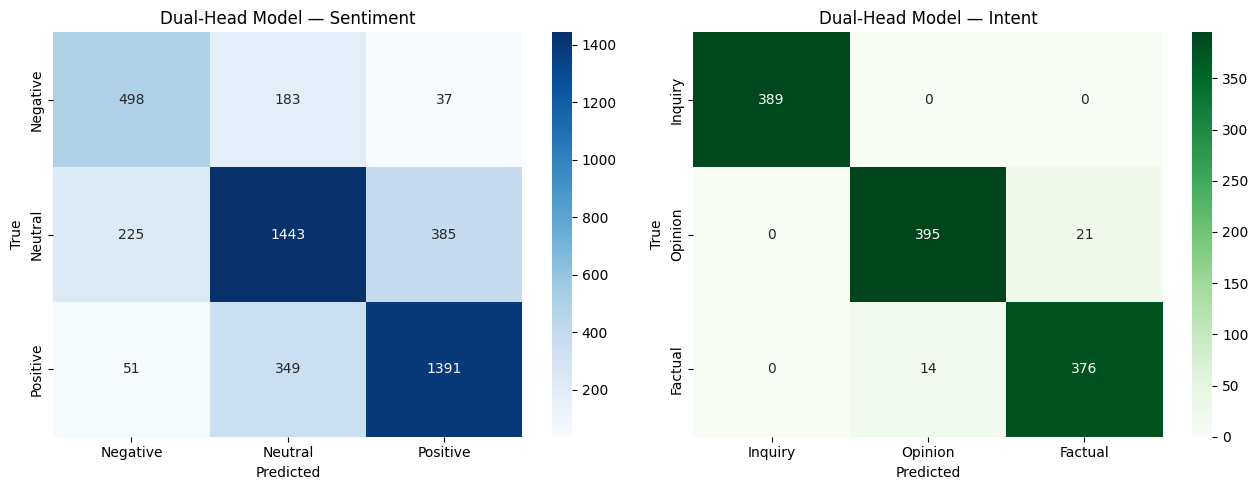

In [19]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def get_predictions_and_labels(trainer, test_df, task_id, task_name):
    task_subset = test_df[test_df["task"] == task_id].reset_index(drop=True)
    task_dataset = Dataset.from_pandas(task_subset[["text", "label", "task"]])
    task_tokenized = task_dataset.map(tokenize_fn, batched=True)

    model.eval()
    all_logits = []
    device = next(model.parameters()).device
    with torch.no_grad():
        for i in range(0, len(task_tokenized), 32):
            batch = task_tokenized[i:i+32]
            input_ids = torch.tensor(batch["input_ids"]).to(device)
            attention_mask = torch.tensor(batch["attention_mask"]).to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs["sentiment_logits"] if task_name == "sentiment" else outputs["intent_logits"]
            all_logits.append(logits.cpu().numpy())
    all_logits = np.concatenate(all_logits, axis=0)
    predictions = np.argmax(all_logits, axis=1)
    true_labels = task_subset["label"].values
    return true_labels, predictions

# Sentiment head
dh_sent_true, dh_sent_pred = get_predictions_and_labels(trainer, test_df, 0, "sentiment")
cm_sent = confusion_matrix(dh_sent_true, dh_sent_pred)
sent_labels = ["Negative", "Neutral", "Positive"]

# Intent head
dh_intent_true, dh_intent_pred = get_predictions_and_labels(trainer, test_df, 1, "intent")
cm_intent = confusion_matrix(dh_intent_true, dh_intent_pred)
intent_labels = ["Inquiry", "Opinion", "Factual"]

# plotting both side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm_sent, annot=True, fmt="d", cmap="Blues", xticklabels=sent_labels, yticklabels=sent_labels, ax=axes[0])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].set_title("Dual-Head Model — Sentiment")

sns.heatmap(cm_intent, annot=True, fmt="d", cmap="Greens", xticklabels=intent_labels, yticklabels=intent_labels, ax=axes[1])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
axes[1].set_title("Dual-Head Model — Intent")

plt.tight_layout()
plt.savefig("/kaggle/working/dualhead_confusion_matrices.png", dpi=150)
plt.show()